# 02 · Acquisition: `acq` and `pe`

The PIC32AK samples the RX chain at 25 Msps (40 ns per sample) and sends 4095 samples to the RP, which prints them
as one number per line after a `# acq …` header. `acq` captures without firing the pulser. `pe` (pulse-echo) fires
the pulser exactly when the capture starts. A transducer on the board gives echoes.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "library"))   # the minus package (or: pip install -e python/library)
import warnings
warnings.filterwarnings("ignore", message="Unable to import Axes3D")   # harmless on mixed matplotlib installs
import numpy as np
import matplotlib.pyplot as plt
from minus import Minus, MinusError
import minus
print("library", minus.__version__, "written for firmware", minus.FIRMWARE)

library 1.1.3 written for firmware {'rp': {'name': 'minus-rp2354', 'version': '1.1.6'}, 'pic': {'name': 'minus-pic32', 'version': '1.1.3'}, 'proto': 13}


In [2]:
dev = Minus()
dev.version().version, dev.pic_ident().version

('1.1.6', '1.1.3')

## 1. `acq`: a capture without a pulse (noise floor)

`acq(div, samc, in_, navg)`: `div` = trigger period in 5 ns counts (4 → 25 Msps), `samc` = ADC sampling time,
`in_` = which node (25 = the filtered RX output, see `minus.INPUTS`), `navg` = conversions summed per sample.
The PIC remembers these settings between calls.

In [3]:
minus.INPUTS

{25: 'AD2AN9: OA2 output after the anti-alias filter (default)',
 17: 'AD2AN1: OA2 output before the filter',
 0: 'AD1AN0: OA1 output',
 1: 'AD1AN1: OA1 input = LNA output',
 19: 'AD2AN3: DACOUT1 (PIC DAC test signal, U9 pin 3)',
 7: 'AD1AN7: DACOUT1 on ADC1'}

In [4]:
a = dev.acq(4, 0, 25, 1)
dev.last.show()

>>> acq 4 0 25 1
<<< # acq n=4095 fill=164.7us fs=24.86Msps rp_fill=160us (RDY window timed by the RP crystal) trigger div 4; in=25 AD2AN9 (PIC32_ADC: OA2OUT after the R67/C86/R68/C87 filter, board 3); navg=1 (12-bit unsigned) link=spi@12.50MHz xfer=5719us
<<< 2003
<<< 2033
<<< 2026
<<< 2031
<<< 2032
<<< ... (4084 more lines) ...
<<< 2034
<<< 2028
<<< 2028
<<< 2035
<<< 2027
<<< 2032
    (4096 lines, 106 ms)


The header line says how long the capture window took, measured by the PIC (`fill`) and independently by the RP
from the RDY line (`rp_fill`), and the resulting sample rate. The `Capture` object holds the samples as a numpy array:

In [5]:
print(a.n, "samples,", a.fs_msps, "Msps,", round(a.dt_ns, 2), "ns/sample, window", a.fill_us, "us")
print("mean %.1f LSB, std %.2f LSB" % (a.samples.mean(), a.samples.std()))
a.samples[:10]

4095 samples, 24.86 Msps, 40.22 ns/sample, window 164.7 us
mean 2030.9 LSB, std 5.51 LSB


array([2003, 2033, 2026, 2031, 2032, 2025, 2032, 2028, 2033, 2025],
      dtype=uint16)

## 2. `gain`: RX gain

Both op-amp stages share one analog mux: `leg` 0..3 picks Rf = 2.2k/4.7k/6.8k/10k (×3.2/×5.7/×7.8/×11 per
stage, before the LNA). `u1`/`u2` = 1 bypasses that stage (×1).

In [6]:
g = dev.gain(2, 0, 0)
dev.last.show()
g

>>> gain 2 0 0
<<< gain leg 2 (Rf 6.8k) OA1 x7.80 OA2 x7.80 = x60.8 (35.7 dB, + LNA)
    (1 lines, 9 ms)


Gain(leg=2, rf_ohm=6800.0, oa1=7.8, oa1_unity=False, oa2=7.8, oa2_unity=False, total=60.8, total_db=35.7)

## 3. `pe`: one pulse-echo A-line

`pe(hi, lo, in_, dead)`: the pulser drives +5 V for `hi` ns, both FETs off for `dead` ns, then GND for `lo` ns.
Defaults 200 / 500 / 27. The reply is the same as `acq` plus a final `# pulse fired, k shot(s)` line. Sometimes the
ADC locks to a slower pattern, so `pe` re-shoots until the sample clock is uniform; `shots` says how many tries it took.

In [7]:
e = dev.pe(200, 500, 25, 27)
dev.last.show()
print("fired:", e.pulse_fired, "| shots:", e.shots)

>>> pe 200 500 25 27
<<< # acq n=4095 fill=164.6us fs=24.87Msps rp_fill=163us (RDY window timed by the RP crystal) pulse-echo: pulse on RDY rise (+5V 200 / off 27 / GND 500 ns), in=25 AD2AN9 (PIC32_ADC: OA2OUT after the R67/C86/R68/C87 filter, board 3), 40 ns/sample; gain leg 2 (Rf 6.8k) OA1 x7.80 OA2 x7.80 = x60.8 (35.7 dB, + LNA); try 1 link=spi@12.50MHz xfer=5717us
<<< 2024
<<< 2036
<<< 2026
<<< 2024
<<< 2043
<<< ... (4085 more lines) ...
<<< 2027
<<< 2036
<<< 2050
<<< 2024
<<< 2035
<<< # pulse fired, 1 shot(s)
    (4097 lines, 106 ms)
fired: True | shots: 1


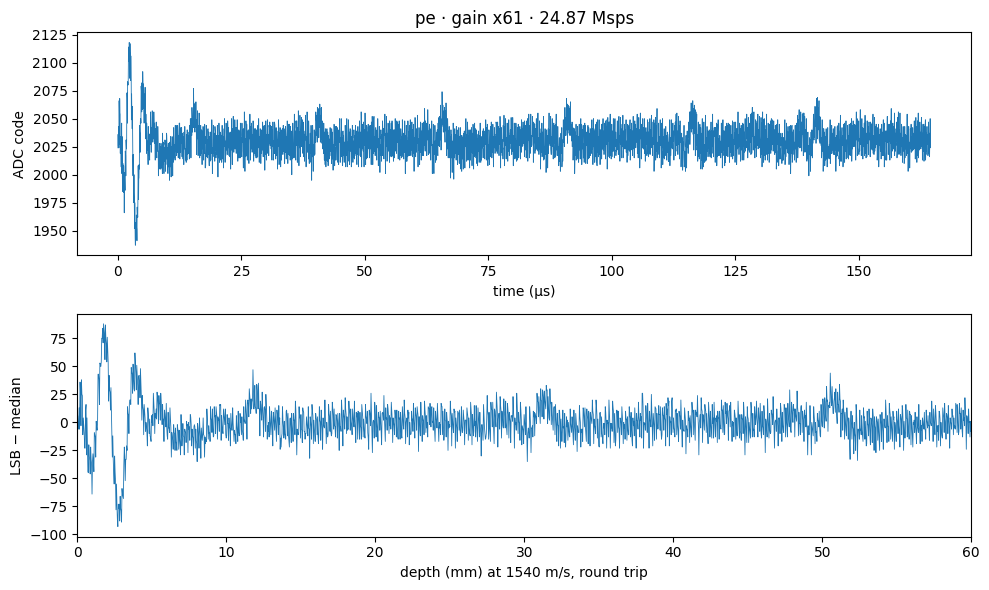

In [8]:
fig, ax = plt.subplots(2, 1, figsize=(10, 6))
ax[0].plot(e.t_us, e.samples, lw=0.6)
ax[0].set(xlabel="time (µs)", ylabel="ADC code", title=f"pe · gain x{g.total:.0f} · {e.fs_msps} Msps")
ax[1].plot(e.depth_mm(), e.samples.astype(float) - np.median(e.samples), lw=0.6)
ax[1].set(xlabel="depth (mm) at 1540 m/s, round trip", ylabel="LSB − median", xlim=(0, 60))
plt.tight_layout()

## 4. Gain sweep

Same pulse, all four legs. The main bang (the transmit pulse leaking into RX) clips at high gain; the echoes grow.

>>> gain 2 0 0
<<< gain leg 2 (Rf 6.8k) OA1 x7.80 OA2 x7.80 = x60.8 (35.7 dB, + LNA)
    (1 lines, 10 ms)


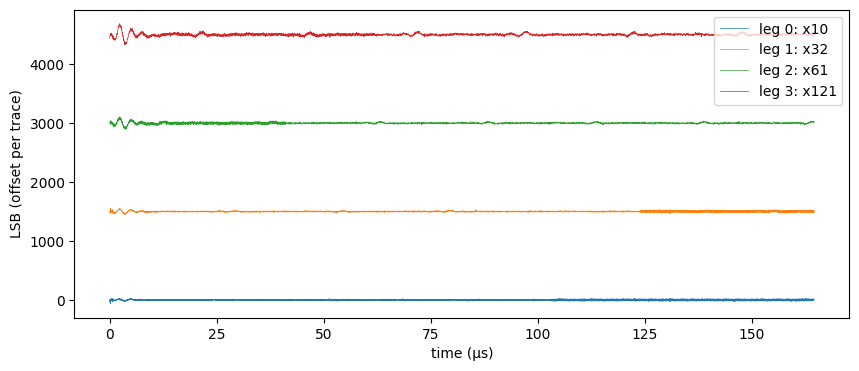

In [9]:
fig, ax = plt.subplots(figsize=(10, 4))
for leg in range(4):
    gl = dev.gain(leg, 0, 0)
    c = dev.pe()
    ax.plot(c.t_us, c.samples.astype(float) - np.median(c.samples) + 1500 * leg, lw=0.5, label=f"leg {leg}: x{gl.total:.0f}")
ax.set(xlabel="time (µs)", ylabel="LSB (offset per trace)"); ax.legend(loc="upper right")
dev.gain(2, 0, 0); dev.last.show()

## 5. `pc`: pattern correction

The ADC shows a small fixed pattern with a period of 4 samples. The PIC subtracts it (on at boot). `pc` reports
the state and the per-phase offsets it removed from the last capture. Compare the noise with it on and off:

In [10]:
for on in (False, True):
    s = dev.pattern_correction(on); dev.last.show()
    c = dev.acq(4, 0, 25, 1)
    x = c.samples.astype(float)
    phase_means = [x[k::4].mean() - x.mean() for k in range(4)]
    print(f"pc {'on ' if on else 'off'}: std {x.std():.2f} LSB, period-4 means {np.round(phase_means, 2)}")
print(dev.pattern_correction())

>>> pc 0
<<< pattern correction off; last capture offsets (LSB, phase 0..3): +8.94 -2.88 -11.56 +5.50
    (1 lines, 6 ms)


pc off: std 13.75 LSB, period-4 means [  2.66   8.96   5.74 -17.38]
>>> pc 1
<<< pattern correction ON; last capture offsets (LSB, phase 0..3): +8.94 -2.88 -11.56 +5.50
    (1 lines, 5 ms)


pc on : std 9.25 LSB, period-4 means [-0.28  0.02 -0.16  0.42]
PatternCorrection(on=True, offsets_lsb=(2.75, 9.0, 5.81, -17.56))


## 6. Averaging several shots

The sample comb's phase relative to the pulse changes from shot to shot, by up to one sample (40 ns; datasheet E3).
Align shots on a strong echo before averaging them, otherwise the echoes smear. Here: cross-correlate each shot
with the first one around the first echo, apply the sub-sample shift in the Fourier domain, then average.

shot lags vs shot 0 (samples): [   0.    330.4   467.76  -55.27   74.89  276.95  155.15 -103.59]


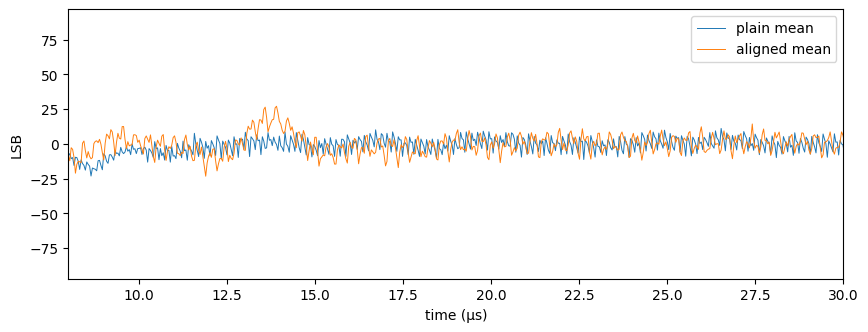

In [11]:
shots = [dev.pe().samples.astype(float) for _ in range(8)]
X = np.array([s - np.median(s) for s in shots])
win = slice(250, 1500)                                     # skip the main bang, keep the first echoes
ref = X[0, win]
def lag_of(x):
    cc = np.correlate(x[win], ref, "full"); k = cc.argmax()
    y0, y1, y2 = cc[k - 1:k + 2]
    return k - (len(ref) - 1) + 0.5 * (y0 - y2) / (y0 - 2 * y1 + y2)
lags = np.array([lag_of(x) for x in X])
f = np.fft.rfftfreq(X.shape[1])
aligned = np.array([np.fft.irfft(np.fft.rfft(x) * np.exp(2j * np.pi * f * l), X.shape[1]) for x, l in zip(X, lags)])
print("shot lags vs shot 0 (samples):", np.round(lags, 2))
t = np.arange(X.shape[1]) * e.dt_ns / 1000
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(t, X.mean(0), lw=0.7, label="plain mean")
ax.plot(t, aligned.mean(0), lw=0.7, label="aligned mean")
ax.set(xlim=(8, 30), xlabel="time (µs)", ylabel="LSB"); ax.legend()

## ADC extras for pulse-echo (rp 1.1.6 / pic 1.1.3, proto 13)

Three PIC functions built on the ADC hardware (design: `docs/claude/specs/2026-11-22-adc-extras-design.md`); here they read
the PIC DAC on AD2AN3 (input 19), since board 3 runs without a piezo in this notebook:

* `acqos(4|16, in_)` — hardware **oversampling**: 4 or 16 conversions per sample, 13 / 14-bit (2× / 4× a 12-bit code),
  175 / 565 ns per sample = 0.72 / 2.3 ms window (deeper, lower noise). One pulse, averaging inside each sample —
  **not an RF mode**: a 3.3 MHz echo aliases at 5.5 / 1.8 Msps and averages out over 128 / 512 ns; use `pe` (RF),
  `env` (echo strength) or `tof` (range) for echoes.
* `tof(thr, blank_ns, in_, ref)` — **time of flight** on the PIC: pulse, capture, first |x − ref| > thr after the blank,
  ADC comparator armed; one line back, no A-line transfer.
* `env(dec, shots, in_)` — **envelope** computed on the PIC (|x − mean| over `dec` samples), averaged over `shots` pulses.

In [12]:
import numpy as np, matplotlib.pyplot as plt
dev.dac("dc", 2048)
for name, c, k in [("acq", dev.acq(4, 0, 19, 1), 1), ("acqos 4", dev.acqos(4, 19), 2), ("acqos 16", dev.acqos(16, 19), 4)]:
    y = c.samples / k
    print(f"{name:9s} dt {c.dt_ns:6.1f} ns  window {c.fill_us:7.1f} us  mean {y.mean():7.1f}  noise {y[64:].std():.2f} LSB rms (12-bit units)")

acq       dt   40.2 ns  window   164.6 us  mean  2029.2  noise 0.85 LSB rms (12-bit units)
acqos 4   dt  180.9 ns  window   740.9 us  mean  2029.3  noise 0.53 LSB rms (12-bit units)
acqos 16  dt  560.4 ns  window  2294.7 us  mean  2028.4  noise 0.33 LSB rms (12-bit units)


In [13]:
dev.dac("dc", 3100); print(dev.tof(1000, 0, 19, 2048))
dev.dac("tri", 512, 3584, 16); t = dev.tof(1000, 0, 19, 2048); dev.last.show(); t

Tof(found=True, index=0, t_ns=0.0, depth_mm=0.0, peak_lsb=1079, peak_index=0, ref=2048, hw_tripped=True, dt_ns=40.22, pulse_fired=True)
>>> tof 1000 0 19 2048
<<< tof: first crossing at sample 22 = 885 ns (1.4 mm round trip -> 0.7 mm at 1540 m/s); peak 1489 LSB at sample 74 (2975 ns); ref 2048 (given); hw comparator tripped; dt=40.21ns; pulse fired
    (1 lines, 9 ms)


Tof(found=True, index=22, t_ns=885.0, depth_mm=0.7, peak_lsb=1489, peak_index=74, ref=2048, hw_tripped=True, dt_ns=40.21, pulse_fired=True)

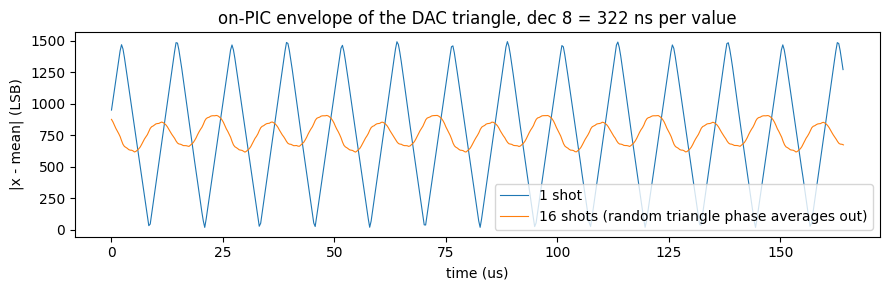

Dac(mode='off', code=None, lo=None, hi=None, slope=None, period_us=None, hz=None, points=None, update_us=None, amp=None, mid=None)

In [14]:
e1, e16 = dev.env(8, 1, 19), dev.env(8, 16, 19)
plt.figure(figsize=(9, 3))
plt.plot(e1.t_us, e1.values, lw=0.8, label="1 shot"); plt.plot(e16.t_us, e16.values, lw=0.8, label="16 shots (random triangle phase averages out)")
plt.xlabel("time (us)"); plt.ylabel("|x - mean| (LSB)"); plt.title(f"on-PIC envelope of the DAC triangle, dec {e1.dec} = {e1.dt_ns:.0f} ns per value")
plt.legend(); plt.tight_layout(); plt.show()
dev.dac("off")

In [15]:
dev.gain(0, 0, 0)
dev.close()